# Hotel Booking Data Analysis

**Course:** Data Processing with Python (HAMK)

**Group members:**
1. Anup Kandel
2. Sandesh Bishokarma
3. Sushant Koirala
4. Tanka Raj Aryal

**Sandesh's working copy.** Only my part is filled in: crosstab (RQ1), groupby (RQ2) and two charts. My numbers use all 1,000 rows until Tanka's cleaning is finished.

Each section below lists what needs to be done (from the project description on Moodle) and who is responsible for it.
The data file is in `../../data/hotel_bookings_final_project.csv`. Do not change it. Save the exported files to `../../outputs/`.

## Context and research questions

Write a short introduction explaining:
- what one row represents;
- the population and time period represented by the data;
- the purpose of your analysis; and
- three research questions.

The questions must collectively include at least one categorical comparison, at least one numerical variable,
and at least one relationship, grouped comparison, or time pattern.

**Responsible:** Tanka Raj Aryal. The three research questions are agreed by the whole group at the kickoff (led by Sandesh Bishokarma).

## Imports and display settings

**Responsible:** Tanka Raj Aryal.

## Load and inspect the data

Use Pandas to load the CSV and inspect the dataset: number of rows and columns; column names and data types;
a small preview or random sample; missing values; exact duplicates; useful category counts; numerical summary statistics.
Do not print large amounts of unnecessary output.

**Responsible:** Tanka Raj Aryal.

## Data-quality assessment and cleaning log

At minimum, investigate: missing values; exact duplicates; invalid date combinations; impossible negative values;
bookings with zero total guests; bookings with zero total nights; unusual values in `lead_time`; unusual values in `average_daily_rate`.

Create a cleaning log as a Markdown table:

| Issue checked | Evidence | Decision | Reason |
|---|---|---|---|
| | | | |

Keep the original DataFrame unchanged and create a cleaned copy.

**Responsible:** Tanka Raj Aryal.

## Transformations and derived variables

Create at least these four derived variables:
- `arrival_date` — proper Pandas date;
- `total_nights` — weekend nights + weekday nights;
- `total_guests` — adults + children + babies;
- `estimated_booking_value` — average daily rate × total nights.

You may create additional useful variables if they support your research questions.

**Responsible:** Sushant Koirala.

## Individual-variable analysis

Analyze at least two categorical variables and two numerical variables.
- Categorical: counts; percentages; valid sample size (n); a suitable chart when useful (bar chart).
- Numerical: valid n; mean; median; standard deviation; minimum and maximum; a suitable visualization such as a histogram or box plot.

**Responsible:** Sushant Koirala.

## Relationships and grouped analysis

Complete at least three grouped or two-variable analyses. Together they must include:
- one categorical-versus-categorical analysis using a crosstab;
- one categorical-versus-numerical analysis using `groupby()` and aggregation; and
- one numerical-versus-numerical or time-based analysis.

For crosstabs, show both counts and clearly labelled percentages. State what the percentage denominator is.

**Responsible:** Sandesh Bishokarma (crosstab for RQ1, groupby for RQ2) and Anup Kandel (time-based analysis for RQ3).

### RQ1: Do cancellation rates differ between the City Hotel and the Resort Hotel?

In [6]:
# Loads the data so my part runs in this working copy (same names as Tanka's notebook).
# In the shared notebook this comes from Tanka's import, load and cleaning sections instead.
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

hotel_raw = pd.read_csv("../../data/hotel_bookings_final_project.csv")
hotel = hotel_raw.copy()
print("Rows and columns:", hotel.shape)

Rows and columns: (1000, 20)


In [7]:
# Readable labels for the cancellation column (uses `hotel`, the cleaned copy from the cleaning section)
hotel["cancel_status"] = "Not cancelled"
hotel.loc[hotel["is_canceled"] == 1, "cancel_status"] = "Cancelled"

# Categorical x categorical: counts with totals
counts = pd.crosstab(hotel["hotel"], hotel["cancel_status"], margins=True, margins_name="Total")
counts

cancel_status,Cancelled,Not cancelled,Total
hotel,,,
City Hotel,279,363,642
Resort Hotel,87,271,358
Total,366,634,1000


In [8]:
# Row percentages: the denominator is all bookings for that hotel (each row adds up to 100 %)
row_pct = (pd.crosstab(hotel["hotel"], hotel["cancel_status"], normalize="index") * 100).round(1)
row_pct

cancel_status,Cancelled,Not cancelled
hotel,,
City Hotel,43.5,56.5
Resort Hotel,24.3,75.7


**Denominator:** each percentage is out of all bookings for that hotel.
City Hotel bookings were cancelled in 43.5 % of cases (279 of 642), against 24.3 % (87 of 358) at the Resort Hotel, a gap of about 19 percentage points.
*(Numbers from all 1,000 rows; re-check them once the cleaning section is finished.)*

In [9]:
# Extra: deposit type x cancellation (denominator = all bookings with that deposit type)
deposit_counts = pd.crosstab(hotel["deposit_type"], hotel["cancel_status"], margins=True, margins_name="Total")
deposit_pct = (pd.crosstab(hotel["deposit_type"], hotel["cancel_status"], normalize="index") * 100).round(1)
print(deposit_counts)
print()
print(deposit_pct)

cancel_status  Cancelled  Not cancelled  Total
deposit_type                                  
No Deposit           250            631    881
Non Refund           116              0    116
Refundable             0              3      3
Total                366            634   1000

cancel_status  Cancelled  Not cancelled
deposit_type                           
No Deposit          28.4           71.6
Non Refund         100.0            0.0
Refundable           0.0          100.0


All 116 Non Refund bookings were cancelled, compared with 28.4 % of No Deposit bookings (n = 881). That is unusual, because people rarely cancel bookings they can't get refunded, so it may come from how the original data recorded these bookings. We report it with caution and don't draw a conclusion from it.

### RQ2: Is lead time associated with cancellation?

In [10]:
# Categorical x numerical: lead time grouped by cancellation status
lead_summary = (
    hotel.groupby("cancel_status", observed=True)
    .agg(
        bookings=("lead_time", "count"),
        average_lead_time=("lead_time", "mean"),
        median_lead_time=("lead_time", "median"),
        std_lead_time=("lead_time", "std"),
    )
    .sort_values("median_lead_time")
    .round(2)
)
lead_summary

,bookings,average_lead_time,median_lead_time,std_lead_time
cancel_status,,,,
Not cancelled,634,83.46,48.0,93.90
Cancelled,366,142.49,117.0,116.21


In [11]:
# Cancellation rate by lead-time band (pd.cut, like rental_level in 01_Pandas_Concepts)
lead_band = pd.cut(
    hotel["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, float("inf")],
    labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"],
)
band_summary = (
    hotel.groupby(lead_band, observed=True)
    .agg(
        bookings=("is_canceled", "count"),
        cancelled=("is_canceled", "sum"),
        cancel_rate_pct=("is_canceled", "mean"),
    )
)
band_summary["cancel_rate_pct"] = (band_summary["cancel_rate_pct"] * 100).round(1)
band_summary

,bookings,cancelled,cancel_rate_pct
lead_time,,,
0-7,145,20,13.8
8-30,170,45,26.5
31-90,253,86,34.0
91-180,220,94,42.7
181-365,184,103,56.0
366+,28,18,64.3


Cancelled bookings were made much further ahead: the median lead time is 117 days, compared with 48 days for bookings that were kept (mean 142 vs 83 days). We use the median because a few very early bookings pull the mean up.
The cancellation rate goes up in every lead-time band, from 13.8 % for bookings made within a week of arrival to 64.3 % for bookings made more than a year ahead (only 28 bookings in that last band).
This is an association: booking early does not by itself cause a cancellation.

## Final visualizations

At least four finished visualizations (Matplotlib or Pandas plotting): one categorical comparison; one numerical distribution;
one relationship or grouped comparison; one time-based or multi-group figure.

Each needs a descriptive title, clear axis labels, a legend when needed, readable labels, sensible formatting, and the sample size (n).
After each, write a short **What can we observe?** paragraph without unsupported causal claims.

**Responsible:** Anup Kandel puts the final four together. Categorical and grouped comparison: Sandesh Bishokarma. Numerical distribution: Sushant Koirala. Time-based figure: Anup Kandel.

### Categorical comparison: cancellation rate by hotel (RQ1)

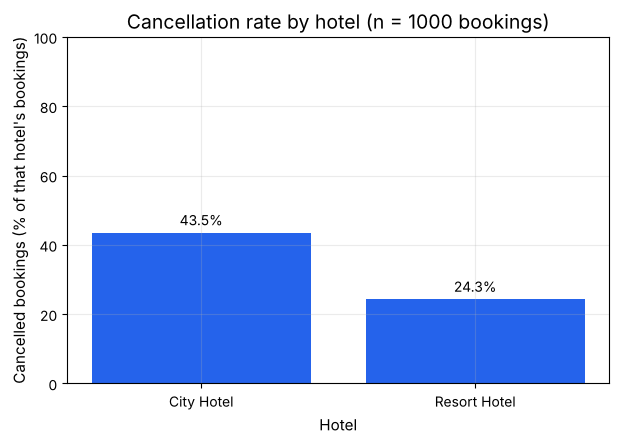

In [13]:
hotel_rate = hotel.groupby("hotel").agg(
    bookings=("is_canceled", "count"),
    cancel_rate_pct=("is_canceled", "mean"),
)
hotel_rate["cancel_rate_pct"] = (hotel_rate["cancel_rate_pct"] * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(hotel_rate.index, hotel_rate["cancel_rate_pct"], color="#2563eb")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title(f"Cancellation rate by hotel (n = {hotel_rate['bookings'].sum()} bookings)")
ax.set_xlabel("Hotel")
ax.set_ylabel("Cancelled bookings (% of that hotel's bookings)")
ax.set_ylim(0, 100)
plt.show()

**What can we observe?** City Hotel bookings were cancelled more often: 43.5 % of its 642 bookings, compared with 24.3 % of the Resort Hotel's 358. The chart shows that the hotels differ, but not why; they also differ in customers, booking channels and lead times.

### Grouped comparison: lead time of kept and cancelled bookings (RQ2)

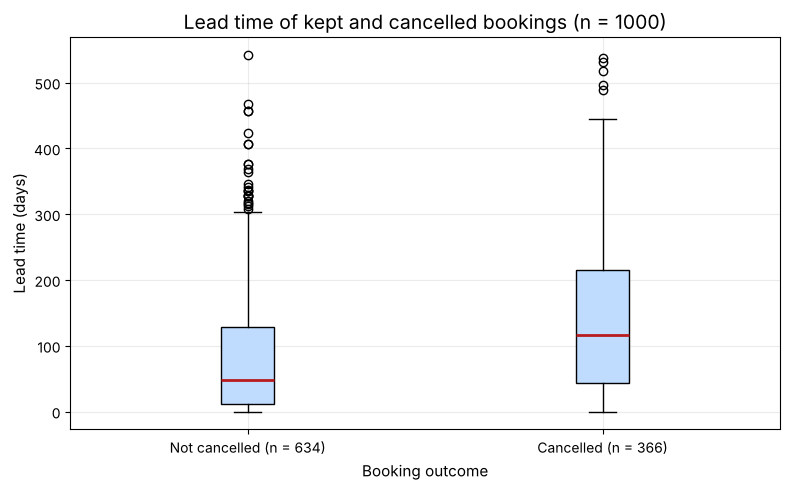

In [14]:
groups = ["Not cancelled", "Cancelled"]
lead_by_group = [hotel.loc[hotel["cancel_status"] == g, "lead_time"] for g in groups]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    lead_by_group,
    tick_labels=[f"{g} (n = {len(d)})" for g, d in zip(groups, lead_by_group)],
    patch_artist=True,
    boxprops={"facecolor": "#bfdbfe"},
    medianprops={"color": "#b91c1c", "linewidth": 2},
)
ax.set_title(f"Lead time of kept and cancelled bookings (n = {len(hotel)})")
ax.set_xlabel("Booking outcome")
ax.set_ylabel("Lead time (days)")
fig.tight_layout()
plt.show()

**What can we observe?** The box for cancelled bookings sits clearly higher: their median lead time is 117 days, compared with 48 days for kept bookings, and 13 of the 20 bookings made more than 400 days ahead were cancelled. Lead time is associated with cancellation in this sample, but we can't say that booking early causes it.

## Conclusions, limitations, and recommendation

- answers to the three research questions;
- three to five evidence-based findings;
- at least two limitations or cautions;
- one recommendation for the hotel-management audience; and
- one useful next question that cannot be answered with the supplied variables.

**Responsible:** Whole group, led by Sandesh Bishokarma.

## Exports and verification

Export at least `hotel_bookings_cleaned.csv` (cleaned dataset) and `hotel_booking_summary.csv` (one useful summary table).
Read the exported files back into Python and verify their shape and key columns.

**Responsible:** Anup Kandel.